In [2]:
import matplotlib.pyplot as plt
import numpy as np

plt.style.use("seaborn-v0_8")

In [3]:
#Data Generate X,Y
def generateDataset(m):
    X=np.random.randn(m)*10
    noise=np.random.randn(m)
    Y=3*X+1+5*noise
    return X,Y

In [4]:
X,Y=generateDataset(100)
print(X.shape,Y.shape)

(100,) (100,)


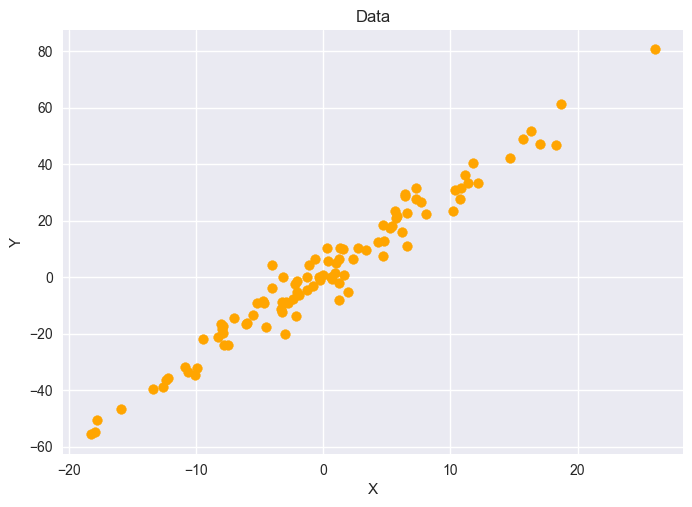

In [6]:
def plotData(X,Y,color="orange",title="Data"):
    plt.title(title)
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.scatter(X,Y,c=color)
    plt.show()

plotData(X,Y)

In [7]:
#Data Normalization
print(X.mean())

0.2814275775607404


In [8]:
print(X.std())

8.534303030451413


In [9]:
def normaliseData(X):
    X=(X-X.mean())/X.std()
    return X

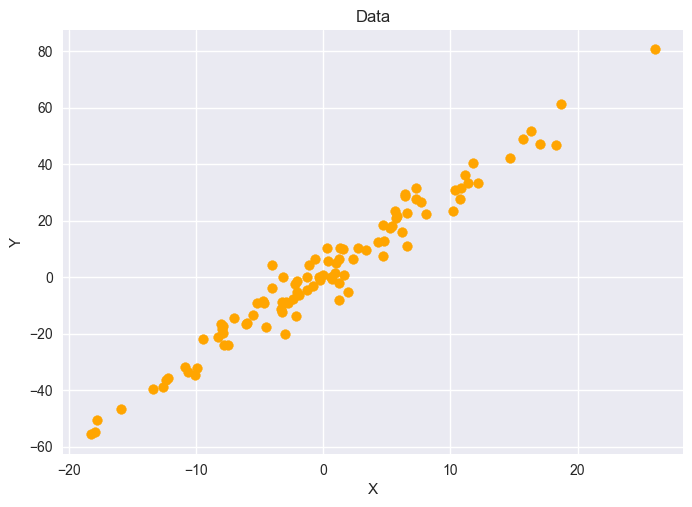

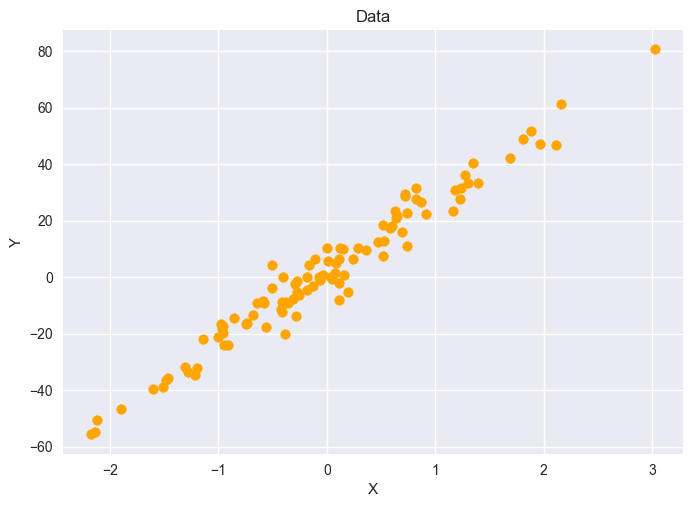

In [10]:
plotData(X,Y)
X=normaliseData(X)
plotData(X,Y)

In [11]:
X.std()

0.9999999999999999

In [12]:
X.mean()

3.1086244689504386e-17

In [13]:
#Train Test Split
def trainTestSplit(X,Y,split=0.8):
    m=X.shape[0]

    data=np.zeros((m,2))

    data[:,0]=X
    data[:,1]=Y

    np.random.shuffle(data)

    split=int(m * split)

    XT = data[:split,0]
    YT = data[:split,1]
    Xt= data[split:,0]
    Yt= data[split:,1]

    return XT, YT, Xt, Yt

In [14]:
XT,YT,Xt,Yt=trainTestSplit(X,Y)

In [15]:
print(XT.shape,YT.shape)
print(Xt.shape,Yt.shape)

(80,) (80,)
(20,) (20,)


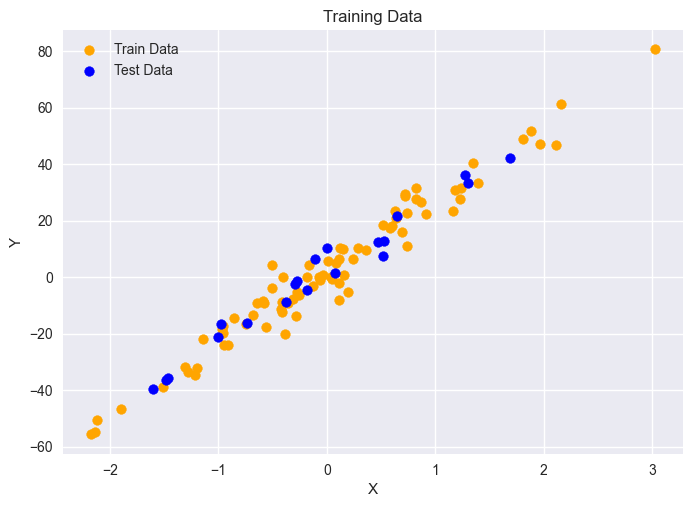

In [16]:
plt.scatter(XT,YT,color="orange",label="Train Data")
plt.scatter(Xt,Yt,color="blue",label="Test Data")
plt.title("Training Data")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.show()

In [18]:
#Modelling
#Hypothesis Func
def Hypothesis(X,theta):
    return theta[0]+theta[1]*X

#ErrorFunc
def error(X,Y,theta):
    m=X.shape[0]
    e=0
    for i in range(m):
        Y_i=Hypothesis(X[i],theta)
        e=e+(Y[i]-Y_i)**2

    return e/2*m

#Gradient Func
def gradientDescent(X,Y,theta):
    m=X.shape[0]
    grad=np.zeros((2,))

    for i in range(m):
        exp=Hypothesis(X[i],theta)-Y[i]
        grad[0] += (exp)
        grad[1] += (X[i]*(exp))

    return grad/m

#Train Func
def train(X,Y,lr=0.1):
        theta=np.zeros((2,))

        max_ITrs=100
        error_list=[]

        for i in range(max_ITrs):
            grad=gradientDescent(X,Y,theta)
            error_list.append(error(X,Y,theta))
            theta[0]=theta[0]-lr*grad[0]
            theta[1]=theta[1]-lr*grad[1]
        plt.plot(error_list)
        plt.xlabel("Iteration")
        plt.ylabel("Loss")
        return theta

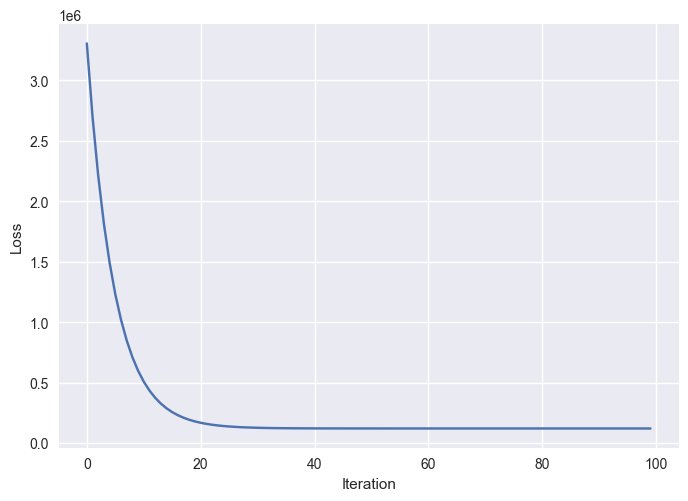

In [20]:
theta=train(X,Y)

In [21]:
#Prediction
theta

array([ 2.03860054, 25.15883893])

In [22]:
def predict(X,theta):
    return Hypothesis(X,theta)

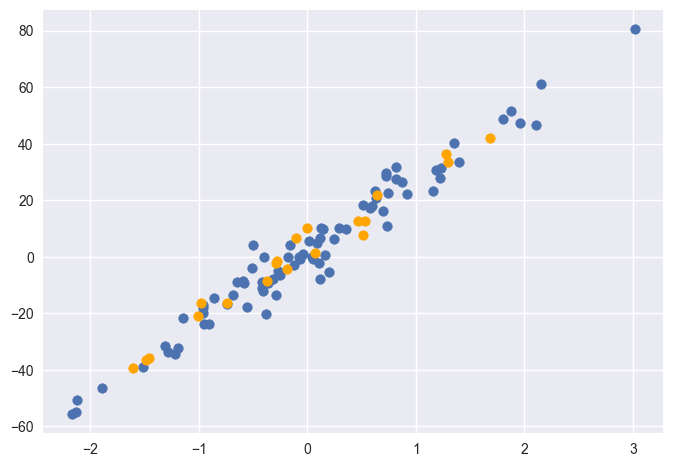

In [23]:
plt.scatter(XT,YT,)
plt.scatter(Xt,Yt,color="orange")
plt.show()

In [24]:
yp=predict(Xt,theta)

In [25]:
Xt.shape

(20,)

In [26]:
yp.shape

(20,)

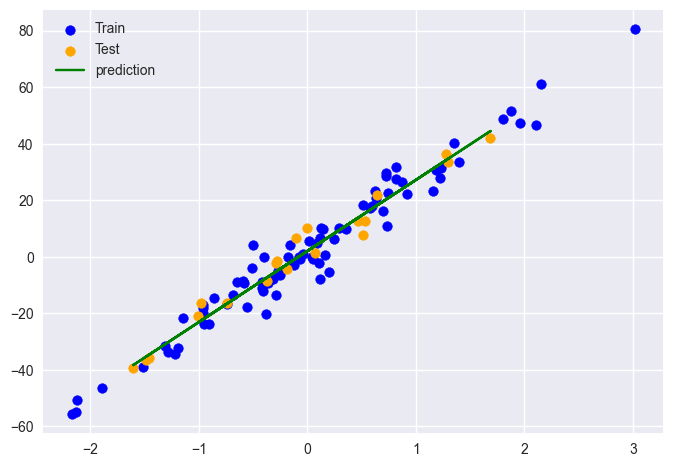

In [27]:
plt.scatter(XT,YT,color="blue",label='Train')
plt.scatter(Xt,Yt,color="orange",label='Test')
plt.plot(Xt,yp,color="green",label='prediction')
plt.legend()
plt.show()

In [28]:
#Model Evaluation
def R2SCORE(Y,yp):
    Ymean=Y.mean()
    num=np.sum((Y-yp)**2)
    denom=np.sum((Y-Ymean)**2)
    return 1-num/denom
R2SCORE(Yt,yp)

0.9728358368554343

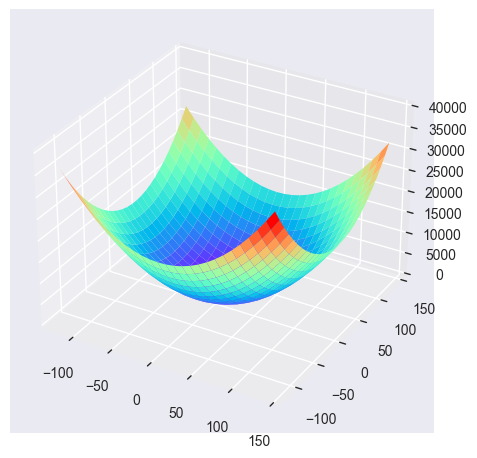

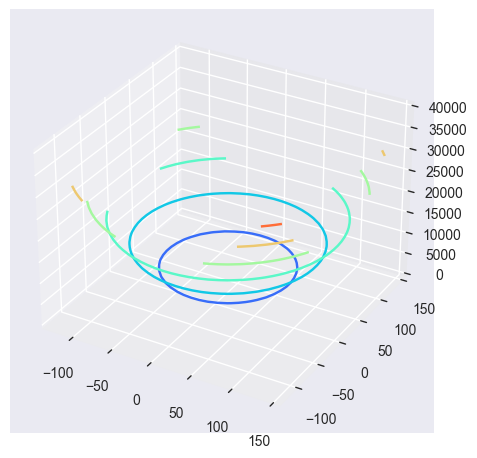

In [30]:
#Visualizing
T0=np.arange(-120,150,10)
T1=np.arange(-120,150,10)

T0,T1=np.meshgrid(T0,T1)
J=np.zeros(T0.shape)
for i in range(J.shape[0]):
    for j in range(J.shape[1]):
        yp=T1[i,j]*X + T0[i,j]
        J[i,j]=np.mean((Y-yp)**2)

fig=plt.figure()
axes=fig.add_subplot(projection='3d')
axes.plot_surface(T0,T1,J,cmap='rainbow')
plt.show()

fig=plt.figure()
axes=fig.add_subplot(projection='3d')
axes.contour(T0,T1,J,cmap='rainbow')
plt.show()

In [46]:
#Trajectory
def Train(X,Y,lr=0.1,maxIter=100):
    theta=np.zeros((2,))
    error_list=[]
    #note down values of theta
    theta_list=[]


    for i in range(maxIter):
        grad=gradientDescent(X,Y,theta)
        error_list.append(error(X,Y,theta))
        theta_list.append((theta[0],theta[1]))
        theta[0]=theta[0]-lr*grad[0]
        theta[1]=theta[1]-lr*grad[1]

    return theta,theta_list,error_list

In [47]:
theta,theta_list,error_list=Train(XT,YT)

In [48]:
theta_list=np.array(theta_list)

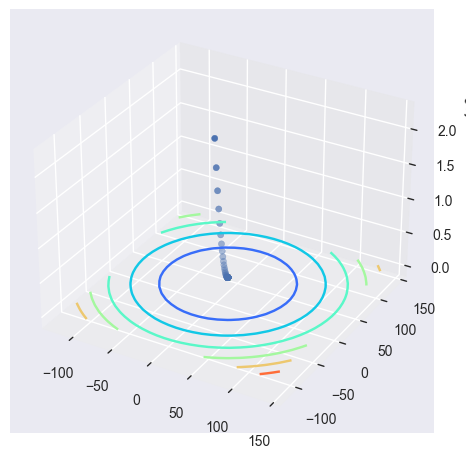

In [49]:
fig=plt.figure()
axes=fig.add_subplot(projection='3d')
axes.contour(T0,T1,J,cmap='rainbow')
axes.scatter(theta_list[:,0],theta_list[:,1],error_list)
plt.show()

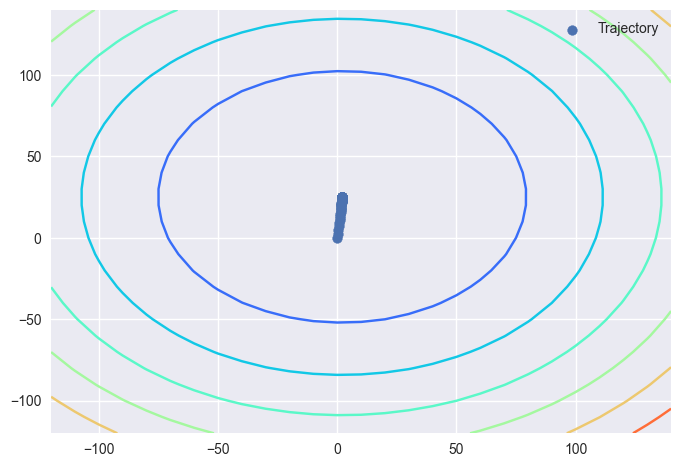

In [50]:
#2d Trajectory Top View
plt.contour(T0,T1,J,cmap='rainbow')
plt.scatter(theta_list[:,0],theta_list[:,1],label="Trajectory")
plt.legend()
plt.show()